In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("Books_Data_Clean.csv")

# Initial investigation

In [9]:
print(df.shape)

(1070, 15)


In [10]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1070 entries, 0 to 1069
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   index                1070 non-null   int64  
 1   Publishing Year      1069 non-null   float64
 2   Book Name            1047 non-null   str    
 3   Author               1070 non-null   str    
 4   language_code        1017 non-null   str    
 5   Author_Rating        1070 non-null   str    
 6   Book_average_rating  1070 non-null   float64
 7   Book_ratings_count   1070 non-null   int64  
 8   genre                1070 non-null   str    
 9   gross sales          1070 non-null   float64
 10  publisher revenue    1070 non-null   float64
 11  sale price           1070 non-null   float64
 12  sales rank           1070 non-null   int64  
 13  Publisher            1070 non-null   str    
 14  units sold           1070 non-null   int64  
dtypes: float64(5), int64(4), str(6)
memory usage: 125

In [12]:
print(df.dtypes)

index                    int64
Publishing Year        float64
Book Name                  str
Author                     str
language_code              str
Author_Rating              str
Book_average_rating    float64
Book_ratings_count       int64
genre                      str
gross sales            float64
publisher revenue      float64
sale price             float64
sales rank               int64
Publisher                  str
units sold               int64
dtype: object


In [15]:
print(df.isnull().sum())

index                   0
Publishing Year         1
Book Name              23
Author                  0
language_code          53
Author_Rating           0
Book_average_rating     0
Book_ratings_count      0
genre                   0
gross sales             0
publisher revenue       0
sale price              0
sales rank              0
Publisher               0
units sold              0
dtype: int64


In [17]:
print(df.describe().round(2))

         index  Publishing Year  Book_average_rating  Book_ratings_count  \
count  1070.00          1069.00              1070.00             1070.00   
mean    534.50          1971.38                 4.01            94909.91   
std     309.03           185.08                 0.25            31513.24   
min       0.00          -560.00                 2.97            27308.00   
25%     267.25          1985.00                 3.85            70398.00   
50%     534.50          2003.00                 4.01            89309.00   
75%     801.75          2010.00                 4.17           113906.50   
max    1069.00          2016.00                 4.77           206792.00   

       gross sales  publisher revenue  sale price  sales rank  units sold  
count      1070.00            1070.00     1070.00     1070.00     1070.00  
mean       1856.62             843.28        4.87      611.65     9676.98  
std        3936.92            2257.60        3.56      369.85    15370.57  
min        

In [18]:
print(df['genre'].value_counts())

genre
genre fiction    822
nonfiction       171
fiction           62
children          15
Name: count, dtype: int64


In [20]:
df.head()

,index,Publishing Year,Book Name,Author,language_code,Author_Rating,Book_average_rating,Book_ratings_count,genre,gross sales,publisher revenue,sale price,sales rank,Publisher,units sold
0,0,1975.0,Beowulf,"Unknown, Seamus Heaney",en-US,Novice,3.42,155903,genre fiction,34160.0,20496.0,4.88,1,HarperCollins Publishers,7000
1,1,1987.0,Batman: Year One,"Frank Miller, David Mazzucchelli, Richmond Lew...",eng,Intermediate,4.23,145267,genre fiction,12437.5,7462.5,1.99,2,HarperCollins Publishers,6250
2,2,2015.0,Go Set a Watchman,Harper Lee,eng,Novice,3.31,138669,genre fiction,47795.0,28677.0,8.69,3,"Amazon Digital Services, Inc.",5500
3,3,2008.0,When You Are Engulfed in Flames,David Sedaris,en-US,Intermediate,4.04,150898,fiction,41250.0,24750.0,7.50,3,Hachette Book Group,5500
4,4,2011.0,Daughter of Smoke & Bone,Laini Taylor,eng,Intermediate,4.04,198283,genre fiction,37952.5,22771.5,7.99,4,Penguin Group (USA) LLC,4750


Our dataset has 1,070 books and 15 columns of information, like sales, prices, and ratings. Almost all the data is filled in, except for a few missing names and dates (like 23 missing book names and 53 missing languages). Some numbers are very spread out — for example, book prices go up to 33.86 USD, and sales reach 47,795 USD. Also, the categories are not balanced at all: most books belong to "genre fiction" (822 books), while "children" books have only 15.

# Missing Value Handling

In [23]:
df.columns = df.columns.str.strip()
df['language_code'] = df['language_code'].fillna('Unknown')
df['Book Name'] = df['Book Name'].fillna('Unknown')
df['Publishing Year'] = df['Publishing Year'].fillna(df['Publishing Year'].median())

print(df.isnull().sum())

index                  0
Publishing Year        0
Book Name              0
Author                 0
language_code          0
Author_Rating          0
Book_average_rating    0
Book_ratings_count     0
genre                  0
gross sales            0
publisher revenue      0
sale price             0
sales rank             0
Publisher              0
units sold             0
dtype: int64


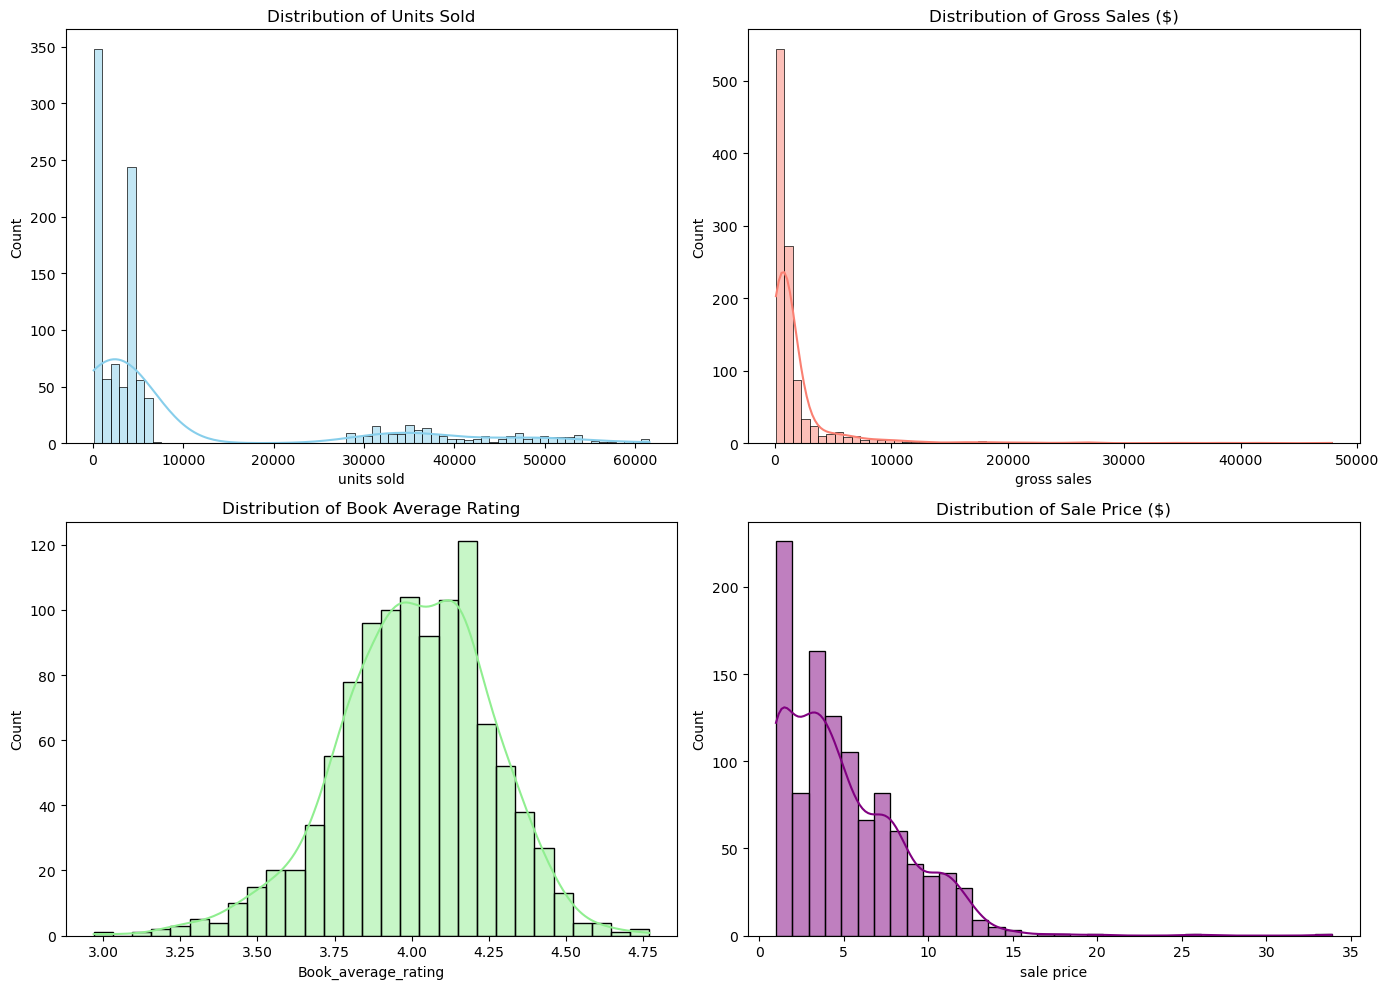

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Distribution of Units Sold
sns.histplot(df['units sold'], kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Distribution of Units Sold')

# Distribution of Gross Sales
sns.histplot(df['gross sales'], kde=True, ax=axes[0, 1], color='salmon')
axes[0, 1].set_title('Distribution of Gross Sales ($)')

# Distribution of Book Average Ratings
sns.histplot(df['Book_average_rating'], kde=True, ax=axes[1, 0], color='lightgreen')
axes[1, 0].set_title('Distribution of Book Average Rating')

# Distribution of Sale Prices
sns.histplot(df['sale price'], kde=True, ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Distribution of Sale Price ($)')

plt.tight_layout()
plt.show()

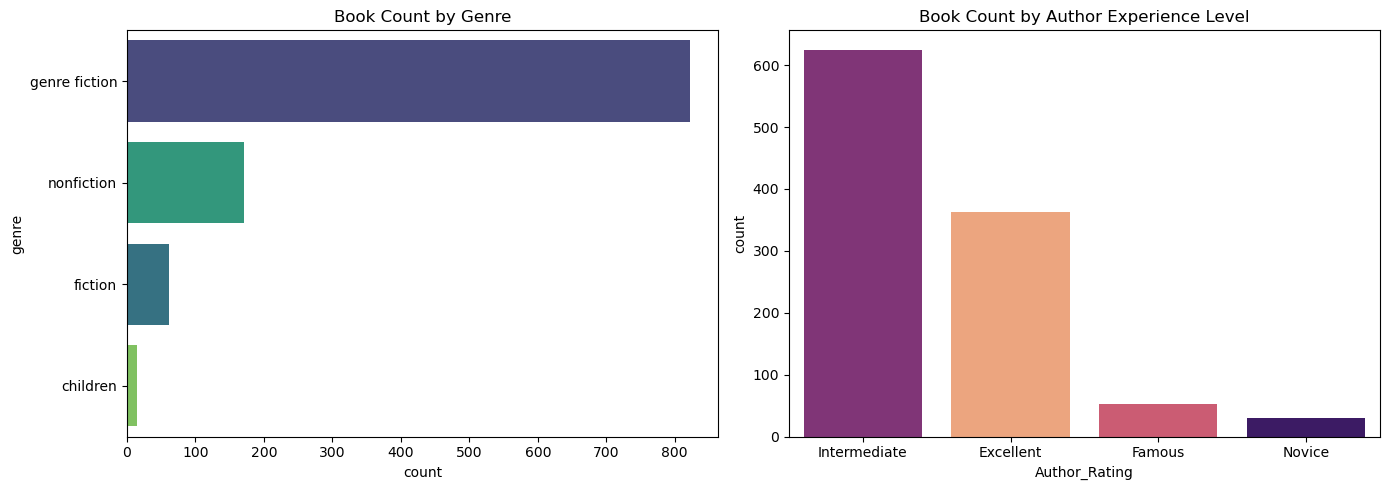

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    y='genre', 
    data=df, 
    order=df['genre'].value_counts().index, 
    ax=axes[0], 
    hue='genre', 
    palette='viridis', 
    legend=False
)
axes[0].set_title('Book Count by Genre')

sns.countplot(
    x='Author_Rating', 
    data=df, 
    order=df['Author_Rating'].value_counts().index, 
    ax=axes[1], 
    hue='Author_Rating', 
    palette='magma', 
    legend=False
)
axes[1].set_title('Book Count by Author Experience Level')

plt.tight_layout()
plt.show()

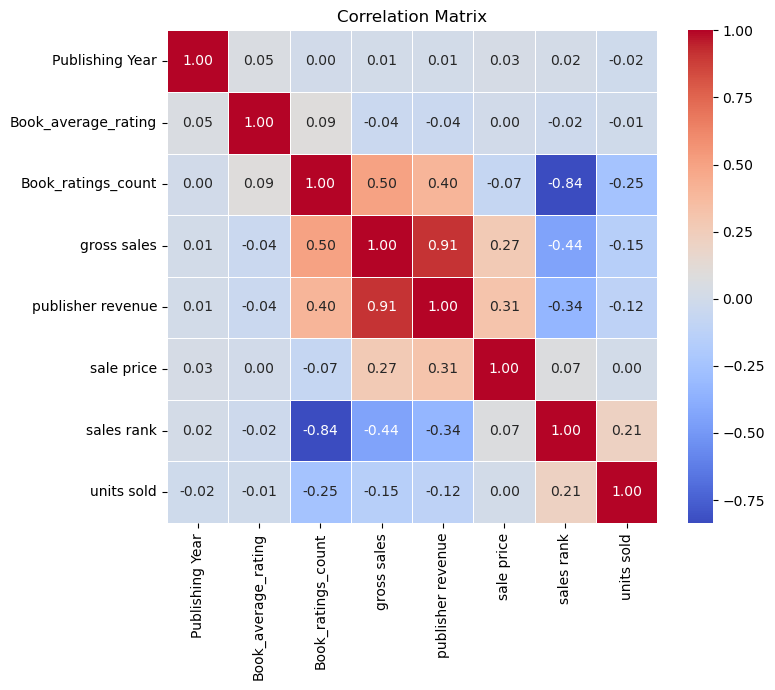

In [35]:
numeric_cols = ['Publishing Year', 'Book_average_rating', 'Book_ratings_count', 
                'gross sales', 'publisher revenue', 'sale price', 'sales rank', 'units sold']

plt.figure(figsize=(8, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

Sales Performance by Genre:
               gross sales  units sold  publisher revenue
genre                                                    
genre fiction   1622694.33     7875834         693682.620
nonfiction       228158.87     1634759         131846.172
fiction          121831.13      545658          68440.578
children          13902.22      298118           8341.332


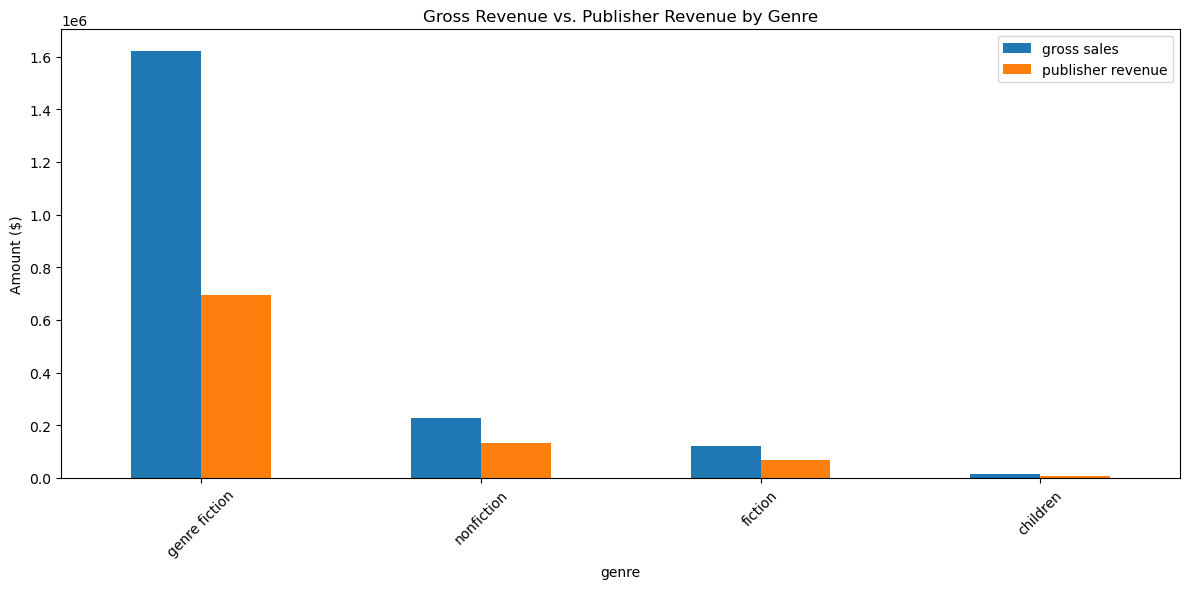

In [36]:
genre_performance = df.groupby('genre')[['gross sales', 'units sold', 'publisher revenue']].sum().sort_values(by='gross sales', ascending=False)

print("Sales Performance by Genre:")
print(genre_performance)

genre_performance[['gross sales', 'publisher revenue']].plot(kind='bar', figsize=(12, 6))
plt.title('Gross Revenue vs. Publisher Revenue by Genre')
plt.ylabel('Amount ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()